# CareerPrep AI — Course & Resource Recommendation System

## Objective
Automatically map learning courses, tutorials, and certification paths to a student's identified skill gaps so they know exactly what to study next.

## Feature Workflow
1. Build a structured catalog of courses with platforms, duration, difficulty, and skill tags.
2. Filter courses based on a student's top skill gap priorities.
3. Sort and present a customized learning roadmap for the student.

## Technology
- Python
- Jupyter Notebook
- pandas (for tabular course catalog management)

In [2]:
# CareerPrep AI
# Step 1: Course Catalog & Recommendation Engine using pandas

import pandas as pd

# Define course database
courses_data = [
    {
        "course_id": "C101",
        "skill": "Data Structures",
        "title": "Data Structures & Algorithms Masterclass",
        "platform": "LeetCode / Udemy",
        "difficulty": "Intermediate",
        "duration": "12 hours"
    },
    {
        "course_id": "C102",
        "skill": "Data Structures",
        "title": "Python Data Structures Essentials",
        "platform": "Coursera",
        "difficulty": "Beginner",
        "duration": "8 hours"
    },
    {
        "course_id": "C103",
        "skill": "Problem Solving",
        "title": "Competitive Programming & Problem Solving Patterns",
        "platform": "HackerRank",
        "difficulty": "Intermediate",
        "duration": "15 hours"
    },
    {
        "course_id": "C104",
        "skill": "SQL",
        "title": "SQL for Data Analysis & Database Design",
        "platform": "DataCamp",
        "difficulty": "Beginner",
        "duration": "10 hours"
    },
    {
        "course_id": "C105",
        "skill": "Python",
        "title": "Complete Python Bootcamp: Zero to Hero",
        "platform": "Udemy",
        "difficulty": "Beginner-Intermediate",
        "duration": "22 hours"
    },
    {
        "course_id": "C106",
        "skill": "Git and GitHub",
        "title": "Git & GitHub Version Control Fundamental",
        "platform": "YouTube / freeCodeCamp",
        "difficulty": "Beginner",
        "duration": "4 hours"
    }
]

# Convert dictionary list to pandas DataFrame
course_df = pd.DataFrame(courses_data)

def recommend_courses(student_profile, career_requirements, catalog_df):
    target_career = student_profile["target_career"]
    required_skills = career_requirements.get(target_career, {})
    current_skills = student_profile["current_skills"]
    
    # Calculate skill gaps
    gaps = {}
    for skill, target in required_skills.items():
        current = current_skills.get(skill, 0)
        gap = max(0, target - current)
        if gap > 0:
            gaps[skill] = gap
            
    # Sort by highest gap first
    sorted_gaps = sorted(gaps.items(), key=lambda item: item[1], reverse=True)
    
    print(f"==================================================")
    print(f" RECOMMENDED LEARNING PATH FOR: {student_profile['name'].upper()}")
    print(f" Target Role: {target_career}")
    print(f"==================================================\n")
    
    if not sorted_gaps:
        print("🎉 You have met all target proficiencies for this role! No remedial courses needed.")
        return
    
    # Recommend courses for top gap skills
    for skill, gap in sorted_gaps:
        matching_courses = catalog_df[catalog_df["skill"] == skill]
        
        if not matching_courses.empty:
            print(f"📚 High-Priority Skill: {skill} (Gap: {gap}%)")
            for _, row in matching_courses.iterrows():
                print(f"   • [{row['course_id']}] {row['title']}")
                print(f"     Platform: {row['platform']} | Difficulty: {row['difficulty']} | Duration: {row['duration']}")
            print()

# Test profiles
career_requirements = {
    "Python Developer": {
        "Python": 80,
        "SQL": 60,
        "Data Structures": 70,
        "Git and GitHub": 60,
        "Problem Solving": 75
    }
}

shivangi_profile = {
    "name": "Shivangi",
    "target_career": "Python Developer",
    "current_skills": {
        "Python": 60,
        "SQL": 40,
        "Data Structures": 30,
        "Git and GitHub": 50,
        "Problem Solving": 50
    }
}

# Run course recommendations
recommend_courses(shivangi_profile, career_requirements, course_df)

 RECOMMENDED LEARNING PATH FOR: SHIVANGI
 Target Role: Python Developer

📚 High-Priority Skill: Data Structures (Gap: 40%)
   • [C101] Data Structures & Algorithms Masterclass
     Platform: LeetCode / Udemy | Difficulty: Intermediate | Duration: 12 hours
   • [C102] Python Data Structures Essentials
     Platform: Coursera | Difficulty: Beginner | Duration: 8 hours

📚 High-Priority Skill: Problem Solving (Gap: 25%)
   • [C103] Competitive Programming & Problem Solving Patterns
     Platform: HackerRank | Difficulty: Intermediate | Duration: 15 hours

📚 High-Priority Skill: Python (Gap: 20%)
   • [C105] Complete Python Bootcamp: Zero to Hero
     Platform: Udemy | Difficulty: Beginner-Intermediate | Duration: 22 hours

📚 High-Priority Skill: SQL (Gap: 20%)
   • [C104] SQL for Data Analysis & Database Design
     Platform: DataCamp | Difficulty: Beginner | Duration: 10 hours

📚 High-Priority Skill: Git and GitHub (Gap: 10%)
   • [C106] Git & GitHub Version Control Fundamental
     Platf

In [1]:

%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
course_df

,course_id,skill,title,platform,difficulty,duration
0,C101,Data Structures,Data Structures & Algorithms Masterclass,LeetCode / Udemy,Intermediate,12 hours
1,C102,Data Structures,Python Data Structures Essentials,Coursera,Beginner,8 hours
2,C103,Problem Solving,Competitive Programming & Problem Solving Patt...,HackerRank,Intermediate,15 hours
3,C104,SQL,SQL for Data Analysis & Database Design,DataCamp,Beginner,10 hours
4,C105,Python,Complete Python Bootcamp: Zero to Hero,Udemy,Beginner-Intermediate,22 hours
5,C106,Git and GitHub,Git & GitHub Version Control Fundamental,YouTube / freeCodeCamp,Beginner,4 hours


In [5]:
def get_priority(gap):
    if gap >= 30:
        return "High"
    elif gap >= 15:
        return "Medium"
    else:
        return "Low"


# Calculate skill gaps again
required_skills = career_requirements["Python Developer"]
current_skills = shivangi_profile["current_skills"]

gaps = {}

for skill, target in required_skills.items():
    current = current_skills.get(skill, 0)
    gap = max(0, target - current)

    if gap > 0:
        gaps[skill] = gap

# Sort skills by gap
sorted_gaps = sorted(
    gaps.items(),
    key=lambda item: item[1],
    reverse=True
)

print("SKILL PRIORITY ANALYSIS")
print("=" * 35)

for skill, gap in sorted_gaps:
    priority = get_priority(gap)
    print(f"{skill}: {gap}% gap - {priority} Priority")

SKILL PRIORITY ANALYSIS
Data Structures: 40% gap - High Priority
Problem Solving: 25% gap - Medium Priority
Python: 20% gap - Medium Priority
SQL: 20% gap - Medium Priority
Git and GitHub: 10% gap - Low Priority


In [6]:
roadmap = []

for skill, gap in sorted_gaps:
    priority = get_priority(gap)

    matching_courses = course_df[course_df["skill"] == skill]

    for _, course in matching_courses.iterrows():
        roadmap.append({
            "Skill": skill,
            "Gap": gap,
            "Priority": priority,
            "Course": course["title"],
            "Platform": course["platform"],
            "Duration": course["duration"]
        })

roadmap_df = pd.DataFrame(roadmap)

roadmap_df

,Skill,Gap,Priority,Course,Platform,Duration
0,Data Structures,40,High,Data Structures & Algorithms Masterclass,LeetCode / Udemy,12 hours
1,Data Structures,40,High,Python Data Structures Essentials,Coursera,8 hours
2,Problem Solving,25,Medium,Competitive Programming & Problem Solving Patt...,HackerRank,15 hours
3,Python,20,Medium,Complete Python Bootcamp: Zero to Hero,Udemy,22 hours
4,SQL,20,Medium,SQL for Data Analysis & Database Design,DataCamp,10 hours
5,Git and GitHub,10,Low,Git & GitHub Version Control Fundamental,YouTube / freeCodeCamp,4 hours


In [7]:
total_hours = 0

for duration in roadmap_df["Duration"]:
    hours = int(duration.split()[0])
    total_hours += hours

print("PERSONALISED LEARNING ROADMAP SUMMARY")
print("=" * 45)
print("Total Recommended Courses:", len(roadmap_df))
print("Total Learning Time:", total_hours, "hours")
print("Highest Priority Skill:", sorted_gaps[0][0])

PERSONALISED LEARNING ROADMAP SUMMARY
Total Recommended Courses: 6
Total Learning Time: 71 hours
Highest Priority Skill: Data Structures


In [8]:
print("=" * 55)
print("          CAREERPREP AI - LEARNING REPORT")
print("=" * 55)

print("Student Name:", shivangi_profile["name"])
print("Target Career:", shivangi_profile["target_career"])

print("\nSKILL IMPROVEMENT PRIORITIES")
print("-" * 55)

for skill, gap in sorted_gaps:
    print(f"{skill}: {gap}% gap ({get_priority(gap)} Priority)")

print("\nRECOMMENDED COURSES")
print("-" * 55)

for index, row in roadmap_df.iterrows():
    print(f"{index + 1}. {row['Course']}")
    print(f"   Skill: {row['Skill']}")
    print(f"   Platform: {row['Platform']}")
    print(f"   Duration: {row['Duration']}")

print("\nLEARNING SUMMARY")
print("-" * 55)
print("Total Courses:", len(roadmap_df))
print("Total Learning Hours:", total_hours)
print("=" * 55)

          CAREERPREP AI - LEARNING REPORT
Student Name: Shivangi
Target Career: Python Developer

SKILL IMPROVEMENT PRIORITIES
-------------------------------------------------------
Data Structures: 40% gap (High Priority)
Problem Solving: 25% gap (Medium Priority)
Python: 20% gap (Medium Priority)
SQL: 20% gap (Medium Priority)
Git and GitHub: 10% gap (Low Priority)

RECOMMENDED COURSES
-------------------------------------------------------
1. Data Structures & Algorithms Masterclass
   Skill: Data Structures
   Platform: LeetCode / Udemy
   Duration: 12 hours
2. Python Data Structures Essentials
   Skill: Data Structures
   Platform: Coursera
   Duration: 8 hours
3. Competitive Programming & Problem Solving Patterns
   Skill: Problem Solving
   Platform: HackerRank
   Duration: 15 hours
4. Complete Python Bootcamp: Zero to Hero
   Skill: Python
   Platform: Udemy
   Duration: 22 hours
5. SQL for Data Analysis & Database Design
   Skill: SQL
   Platform: DataCamp
   Duration: 10 hou

In [9]:
career_requirements = {
    "Python Developer": {
        "Python": 80,
        "SQL": 60,
        "Data Structures": 70,
        "Git and GitHub": 60,
        "Problem Solving": 75
    },

    "Data Scientist": {
        "Python": 80,
        "SQL": 70,
        "Statistics": 80,
        "Machine Learning": 75,
        "Data Visualization": 70
    },

    "Full Stack Developer": {
        "HTML and CSS": 80,
        "JavaScript": 80,
        "Python": 60,
        "SQL": 65,
        "Git and GitHub": 60
    }
}

print("Career requirements updated successfully!")

for career in career_requirements:
    print("-", career)

Career requirements updated successfully!
- Python Developer
- Data Scientist
- Full Stack Developer


In [10]:
additional_courses = [
    {
        "course_id": "C107",
        "skill": "Statistics",
        "title": "Statistics for Data Science",
        "platform": "Khan Academy",
        "difficulty": "Beginner",
        "duration": "10 hours"
    },
    {
        "course_id": "C108",
        "skill": "Machine Learning",
        "title": "Machine Learning for Beginners",
        "platform": "Coursera",
        "difficulty": "Beginner",
        "duration": "15 hours"
    },
    {
        "course_id": "C109",
        "skill": "Data Visualization",
        "title": "Data Visualization with Python",
        "platform": "freeCodeCamp",
        "difficulty": "Beginner",
        "duration": "8 hours"
    },
    {
        "course_id": "C110",
        "skill": "HTML and CSS",
        "title": "HTML and CSS Complete Course",
        "platform": "freeCodeCamp",
        "difficulty": "Beginner",
        "duration": "12 hours"
    },
    {
        "course_id": "C111",
        "skill": "JavaScript",
        "title": "JavaScript Fundamentals",
        "platform": "freeCodeCamp",
        "difficulty": "Beginner",
        "duration": "15 hours"
    }
]

additional_df = pd.DataFrame(additional_courses)

course_df = pd.concat(
    [course_df, additional_df],
    ignore_index=True
)

print("Additional courses added successfully!")
print("Total courses in catalog:", len(course_df))

Additional courses added successfully!
Total courses in catalog: 11


In [11]:
course_df

,course_id,skill,title,platform,difficulty,duration
0,C101,Data Structures,Data Structures & Algorithms Masterclass,LeetCode / Udemy,Intermediate,12 hours
1,C102,Data Structures,Python Data Structures Essentials,Coursera,Beginner,8 hours
2,C103,Problem Solving,Competitive Programming & Problem Solving Patt...,HackerRank,Intermediate,15 hours
3,C104,SQL,SQL for Data Analysis & Database Design,DataCamp,Beginner,10 hours
4,C105,Python,Complete Python Bootcamp: Zero to Hero,Udemy,Beginner-Intermediate,22 hours
5,C106,Git and GitHub,Git & GitHub Version Control Fundamental,YouTube / freeCodeCamp,Beginner,4 hours
6,C107,Statistics,Statistics for Data Science,Khan Academy,Beginner,10 hours
7,C108,Machine Learning,Machine Learning for Beginners,Coursera,Beginner,15 hours
8,C109,Data Visualization,Data Visualization with Python,freeCodeCamp,Beginner,8 hours
9,C110,HTML and CSS,HTML and CSS Complete Course,freeCodeCamp,Beginner,12 hours


In [12]:
data_scientist_profile = {
    "name": "Aarav",
    "target_career": "Data Scientist",
    "current_skills": {
        "Python": 50,
        "SQL": 40,
        "Statistics": 35,
        "Machine Learning": 30,
        "Data Visualization": 45
    }
}

print("Student:", data_scientist_profile["name"])
print("Target Career:", data_scientist_profile["target_career"])

print("\nSkill Gaps:")

required_skills = career_requirements["Data Scientist"]

for skill, target in required_skills.items():
    current = data_scientist_profile["current_skills"].get(skill, 0)
    gap = max(0, target - current)
    print(f"{skill}: {gap}%")

Student: Aarav
Target Career: Data Scientist

Skill Gaps:
Python: 30%
SQL: 30%
Statistics: 45%
Machine Learning: 45%
Data Visualization: 25%


In [13]:
recommend_courses(
    data_scientist_profile,
    career_requirements,
    course_df
)



 RECOMMENDED LEARNING PATH FOR: AARAV
 Target Role: Data Scientist

📚 High-Priority Skill: Statistics (Gap: 45%)
   • [C107] Statistics for Data Science
     Platform: Khan Academy | Difficulty: Beginner | Duration: 10 hours

📚 High-Priority Skill: Machine Learning (Gap: 45%)
   • [C108] Machine Learning for Beginners
     Platform: Coursera | Difficulty: Beginner | Duration: 15 hours

📚 High-Priority Skill: Python (Gap: 30%)
   • [C105] Complete Python Bootcamp: Zero to Hero
     Platform: Udemy | Difficulty: Beginner-Intermediate | Duration: 22 hours

📚 High-Priority Skill: SQL (Gap: 30%)
   • [C104] SQL for Data Analysis & Database Design
     Platform: DataCamp | Difficulty: Beginner | Duration: 10 hours

📚 High-Priority Skill: Data Visualization (Gap: 25%)
   • [C109] Data Visualization with Python
     Platform: freeCodeCamp | Difficulty: Beginner | Duration: 8 hours



In [14]:
full_stack_profile = {
    "name": "Riya",
    "target_career": "Full Stack Developer",
    "current_skills": {
        "HTML and CSS": 40,
        "JavaScript": 35,
        "Python": 50,
        "SQL": 45,
        "Git and GitHub": 30
    }
}

print("Student:", full_stack_profile["name"])
print("Target Career:", full_stack_profile["target_career"])

print("\nRecommended Learning Path:\n")

recommend_courses(
    full_stack_profile,
    career_requirements,
    course_df
)

Student: Riya
Target Career: Full Stack Developer

Recommended Learning Path:

 RECOMMENDED LEARNING PATH FOR: RIYA
 Target Role: Full Stack Developer

📚 High-Priority Skill: JavaScript (Gap: 45%)
   • [C111] JavaScript Fundamentals
     Platform: freeCodeCamp | Difficulty: Beginner | Duration: 15 hours

📚 High-Priority Skill: HTML and CSS (Gap: 40%)
   • [C110] HTML and CSS Complete Course
     Platform: freeCodeCamp | Difficulty: Beginner | Duration: 12 hours

📚 High-Priority Skill: Git and GitHub (Gap: 30%)
   • [C106] Git & GitHub Version Control Fundamental
     Platform: YouTube / freeCodeCamp | Difficulty: Beginner | Duration: 4 hours

📚 High-Priority Skill: SQL (Gap: 20%)
   • [C104] SQL for Data Analysis & Database Design
     Platform: DataCamp | Difficulty: Beginner | Duration: 10 hours

📚 High-Priority Skill: Python (Gap: 10%)
   • [C105] Complete Python Bootcamp: Zero to Hero
     Platform: Udemy | Difficulty: Beginner-Intermediate | Duration: 22 hours



In [16]:
student_name = input("Enter your name: ")

print("\nAvailable Career Paths:")
for career in career_requirements:
    print("-", career)

target_career = input("\nEnter your target career: ")

if target_career in career_requirements:
    print("\nWelcome,", student_name)
    print("Selected Career:", target_career)
else:
    print("\nInvalid career choice. Please try again.")

Enter your name:  anant



Available Career Paths:
- Python Developer
- Data Scientist
- Full Stack Developer



Enter your target career:  Data Scientist



Welcome, anant
Selected Career: Data Scientist


In [17]:
current_skills = {}

print("Enter your current skill levels (0-100):")

for skill in career_requirements[target_career]:

    while True:
        try:
            score = int(input(f"{skill}: "))

            if 0 <= score <= 100:
                current_skills[skill] = score
                break
            else:
                print("Please enter a score between 0 and 100.")

        except ValueError:
            print("Please enter a valid number.")

student_profile = {
    "name": student_name,
    "target_career": target_career,
    "current_skills": current_skills
}

print("\nStudent profile created successfully!")
print(student_profile)

Enter your current skill levels (0-100):


Python:  70
SQL:  78
Statistics:  55
Machine Learning:  56
Data Visualization:  45



Student profile created successfully!
{'name': 'anant', 'target_career': 'Data Scientist', 'current_skills': {'Python': 70, 'SQL': 78, 'Statistics': 55, 'Machine Learning': 56, 'Data Visualization': 45}}


In [18]:
recommend_courses(
    student_profile,
    career_requirements,
    course_df
)

 RECOMMENDED LEARNING PATH FOR: ANANT
 Target Role: Data Scientist

📚 High-Priority Skill: Statistics (Gap: 25%)
   • [C107] Statistics for Data Science
     Platform: Khan Academy | Difficulty: Beginner | Duration: 10 hours

📚 High-Priority Skill: Data Visualization (Gap: 25%)
   • [C109] Data Visualization with Python
     Platform: freeCodeCamp | Difficulty: Beginner | Duration: 8 hours

📚 High-Priority Skill: Machine Learning (Gap: 19%)
   • [C108] Machine Learning for Beginners
     Platform: Coursera | Difficulty: Beginner | Duration: 15 hours

📚 High-Priority Skill: Python (Gap: 10%)
   • [C105] Complete Python Bootcamp: Zero to Hero
     Platform: Udemy | Difficulty: Beginner-Intermediate | Duration: 22 hours



In [19]:
print("=" * 45)
print("       STUDENT SKILL GAP REPORT")
print("=" * 45)

print("Student:", student_profile["name"])
print("Career:", student_profile["target_career"])

print("\nSKILL ANALYSIS")
print("-" * 45)

required_skills = career_requirements[target_career]

for skill, target in required_skills.items():
    current = student_profile["current_skills"].get(skill, 0)
    gap = max(0, target - current)

    priority = get_priority(gap)

    print(f"{skill}: Current = {current}, Required = {target}")
    print(f"Gap = {gap}% | Priority = {priority}")
    print("-" * 45)

       STUDENT SKILL GAP REPORT
Student: anant
Career: Data Scientist

SKILL ANALYSIS
---------------------------------------------
Python: Current = 70, Required = 80
Gap = 10% | Priority = Low
---------------------------------------------
SQL: Current = 78, Required = 70
Gap = 0% | Priority = Low
---------------------------------------------
Statistics: Current = 55, Required = 80
Gap = 25% | Priority = Medium
---------------------------------------------
Machine Learning: Current = 56, Required = 75
Gap = 19% | Priority = Medium
---------------------------------------------
Data Visualization: Current = 45, Required = 70
Gap = 25% | Priority = Medium
---------------------------------------------


In [20]:
recommended_courses = []

for skill, target in career_requirements[target_career].items():

    current = student_profile["current_skills"].get(skill, 0)
    gap = max(0, target - current)

    if gap > 0:
        matching_courses = course_df[course_df["skill"] == skill]

        for _, course in matching_courses.iterrows():
            recommended_courses.append(course)

total_hours = sum(
    int(course["duration"].split()[0])
    for course in recommended_courses
)

print("PERSONALISED LEARNING SUMMARY")
print("=" * 40)
print("Student:", student_profile["name"])
print("Recommended Courses:", len(recommended_courses))
print("Total Learning Hours:", total_hours)

PERSONALISED LEARNING SUMMARY
Student: anant
Recommended Courses: 4
Total Learning Hours: 55


In [21]:
recommended_df = pd.DataFrame(recommended_courses)

recommended_df["Student Name"] = student_profile["name"]
recommended_df["Target Career"] = student_profile["target_career"]

recommended_df.to_csv(
    "student_learning_roadmap.csv",
    index=False
)

print("Learning roadmap saved successfully!")
print("File: student_learning_roadmap.csv")

Learning roadmap saved successfully!
File: student_learning_roadmap.csv


In [22]:
saved_roadmap = pd.read_csv("student_learning_roadmap.csv")

print("EXPORTED STUDENT LEARNING ROADMAP")
print("=" * 45)

saved_roadmap

EXPORTED STUDENT LEARNING ROADMAP


,course_id,skill,title,platform,difficulty,duration,Student Name,Target Career
0,C105,Python,Complete Python Bootcamp: Zero to Hero,Udemy,Beginner-Intermediate,22 hours,anant,Data Scientist
1,C107,Statistics,Statistics for Data Science,Khan Academy,Beginner,10 hours,anant,Data Scientist
2,C108,Machine Learning,Machine Learning for Beginners,Coursera,Beginner,15 hours,anant,Data Scientist
3,C109,Data Visualization,Data Visualization with Python,freeCodeCamp,Beginner,8 hours,anant,Data Scientist


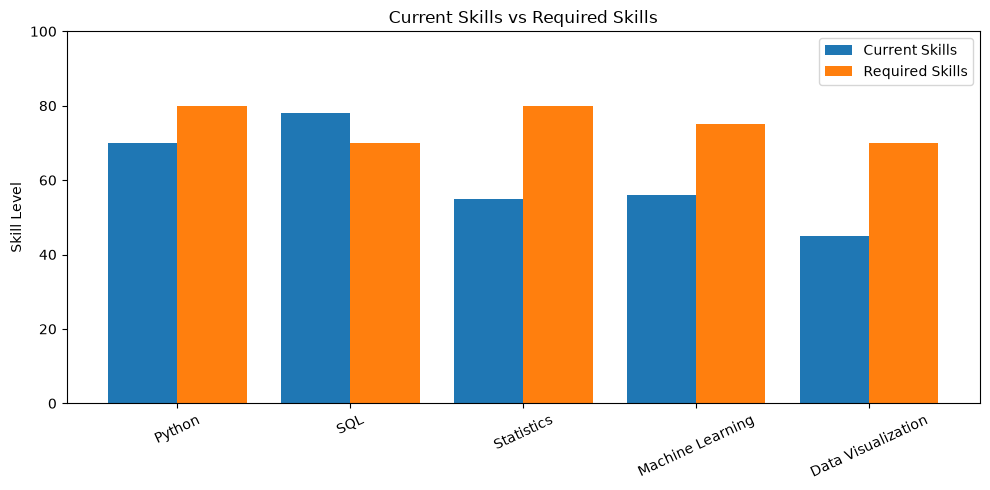

In [23]:
import matplotlib.pyplot as plt

skills = list(student_profile["current_skills"].keys())

current_scores = [
    student_profile["current_skills"][skill]
    for skill in skills
]

required_scores = [
    career_requirements[target_career][skill]
    for skill in skills
]

x = range(len(skills))

plt.figure(figsize=(10, 5))

plt.bar(x, current_scores, width=0.4, label="Current Skills")
plt.bar(
    [i + 0.4 for i in x],
    required_scores,
    width=0.4,
    label="Required Skills"
)

plt.xticks([i + 0.2 for i in x], skills, rotation=25)
plt.ylabel("Skill Level")
plt.title("Current Skills vs Required Skills")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
plt.savefig(
    "skill_gap_chart.png",
    dpi=300,
    bbox_inches="tight"
)

print("Skill gap chart saved successfully!")

Skill gap chart saved successfully!


<Figure size 640x480 with 0 Axes>